# Transformer

Część pierwsza ćwiczeń z transformers

## Po co nowy mechanizm?
 - W tradycyjnych RNN/LSTM informacja przepływa sekwencyjnie. Mechanizmy uwagi natomiast pozwalają modelowi skupić się na różnych częściach wejścia przy generowaniu każdego elementu wyjścia.
 - W Transformerach uwaga jest podstawowym mechanizmem: każdy token oblicza "ważność" innych tokenów przez iloczyn skalarny swoich zapytań (queries) z kluczami (keys) i wykorzystuje wartości (values) do zbudowania reprezentacji.

## Attention is All You Need

Mechanizm, który odpowiada za dobrą reputację transformerów to mechanizm attencji / uwagi. Mechanizm ten został zaprezentowany w research paperze: [Attention is All You Need](https://arxiv.org/abs/1706.03762)

### 1 Wejście

Na wejściu mamy takie zdanie:

```
”The animal didn't cross the street because it was too tired”
```

W tym zdaniu modele językowe moga mieć problem zrozumieć do czego odnosi się słowo 'it".


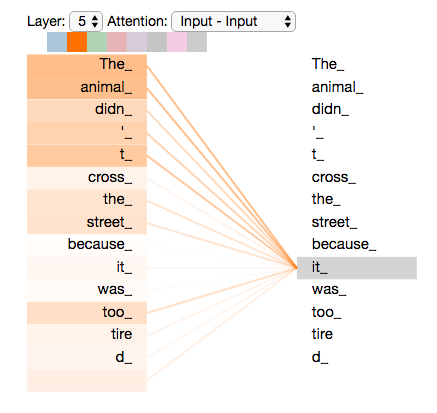

### 2 Embeddingi

Przyszły do nas dwa słowa, które mają swoje odpowiadające embeddingi - x1 i x2

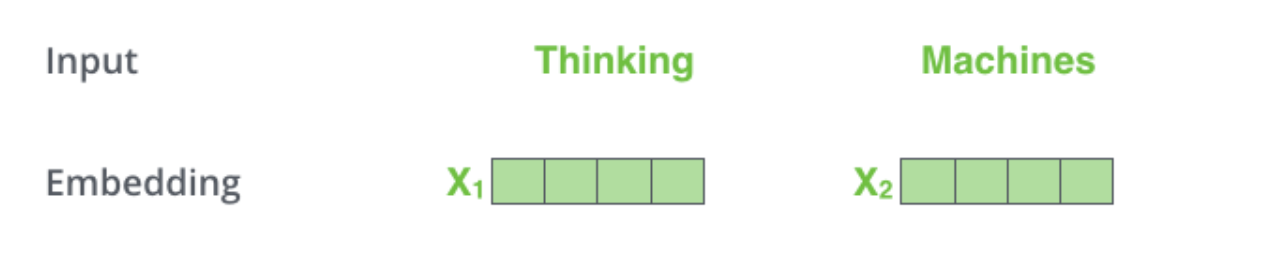

### 3 Query, key i value

- Q: query / zapytania — reprezentacja tego, czego "szukamy".
- K: key / klucze — reprezentacje elementów, do których porównujemy zapytania.
- V: values / wartości — zawierają informacje, które będziemy agregować (przez ważoną sumę).

Podczas treningu modelu tworzymy 3 macierze - wagi dla wartości query, key i value: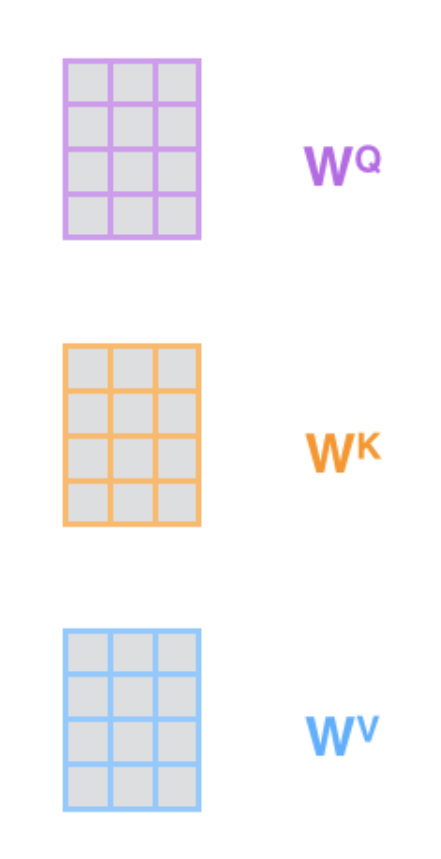

Każde ze słów jest przemnożone przez te macierze:

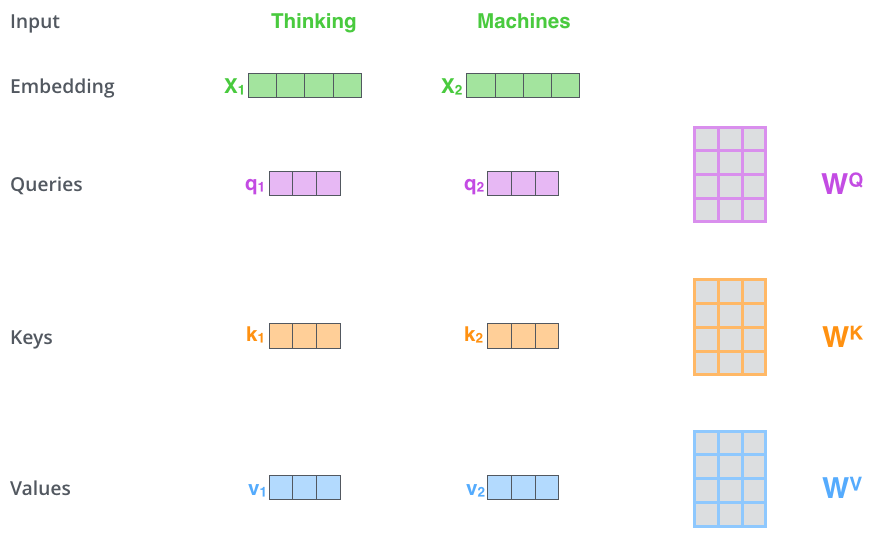

W ten sposób dla każdego słowa (embedingu) otrzymaliśmy wektory query, key i value. Raczej nie tłumaczymy tych słów na język polski.

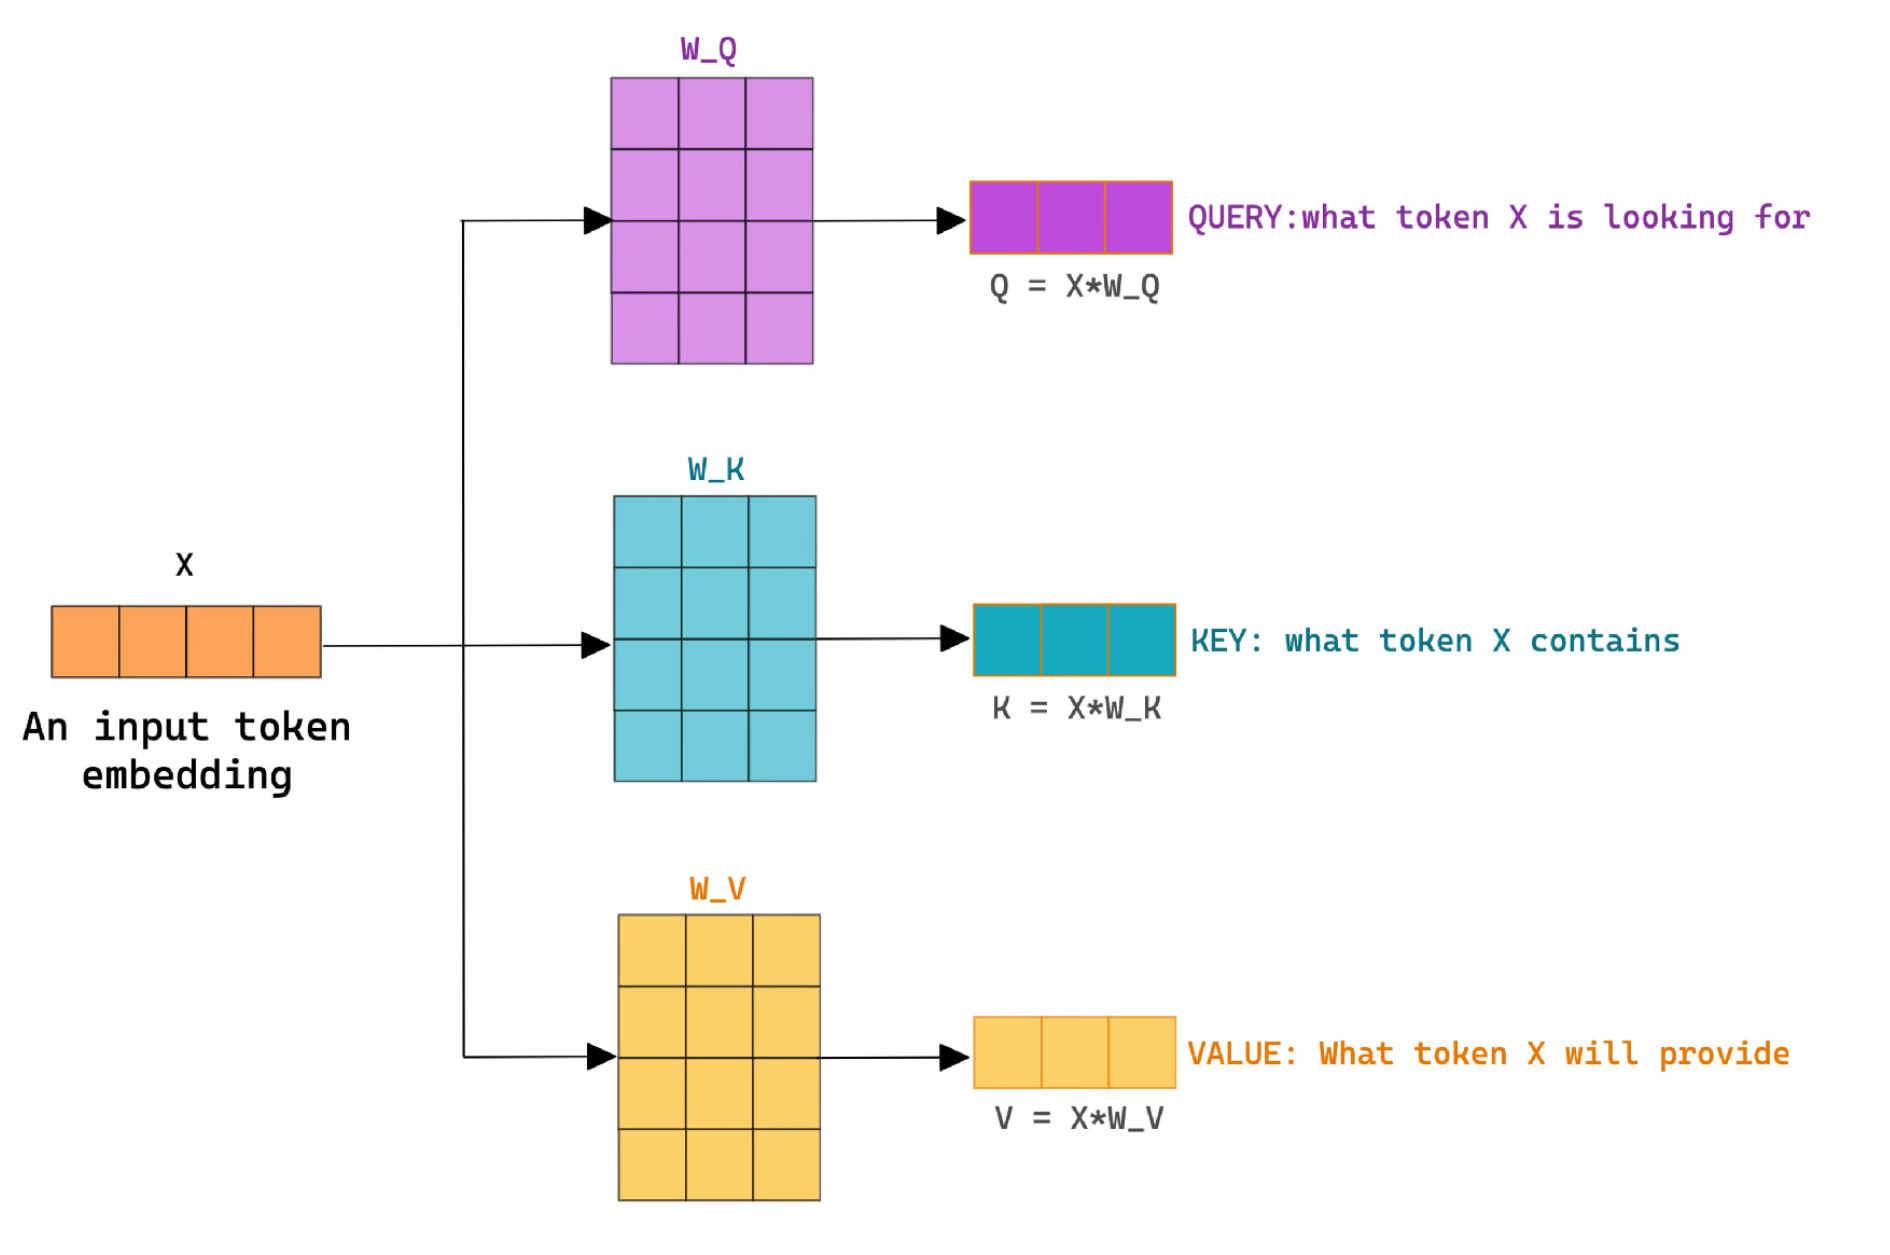

### 4 Obliczenie attention - na wektorach

Obliczamy attention dla pierwszego słowa. Interesuje nas wynik jaki uzyskuje nasze z słowo z KAŻDYM słowem występującym.

Przemnażamy query (tego słowa) * key (po koeli każdego występującego słowa):

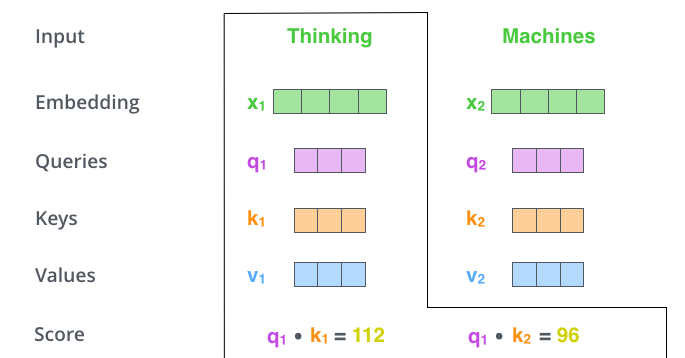

Dzielimy przez pierwiastek z wymiaru wektoru k:

(na podanym przykładzie wzięto wymiar k = 64)

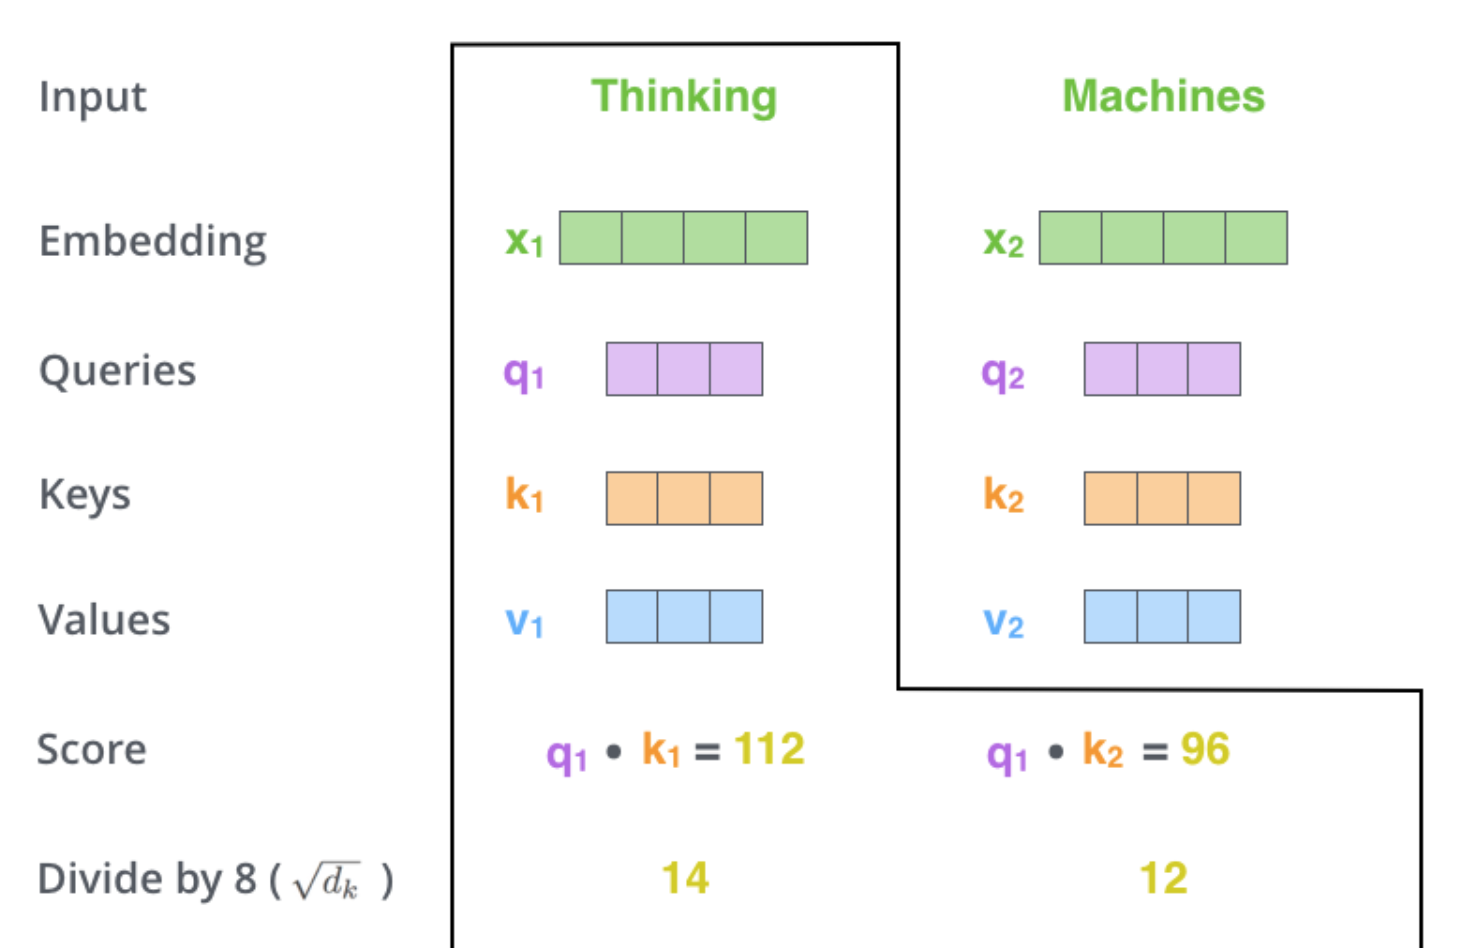

Używamy softmaxa - normalizujemy wartości, żeby wartości były dodatnie i sumowały się do 1.

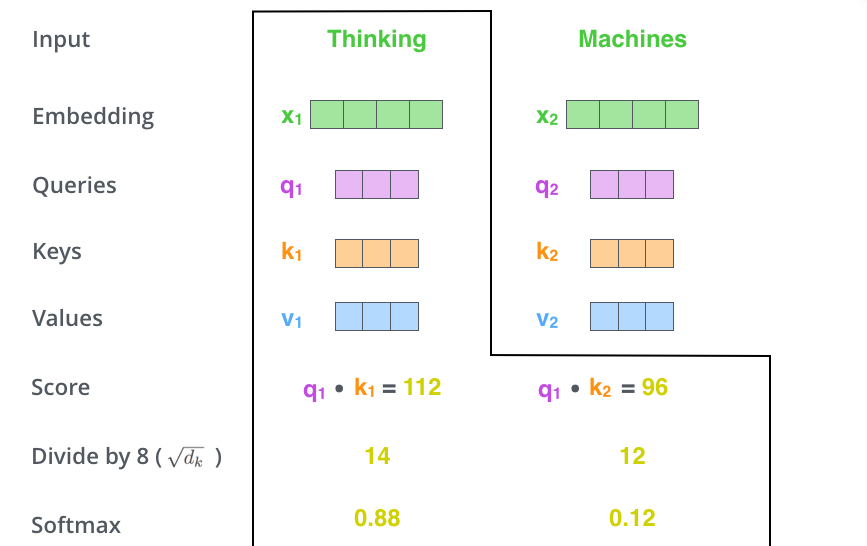

Zauważ, że największy wyniki osiągamy tutaj w liczeniu danego słowa do samego siebie. Jest to naturalne, bo dane słowo reprezentuje siebie najbardziej. Możemy mieć jednak inne słowa, które będą miały wysoki wynik, co oznacza, że mają do siebie jakiś związek (np bird i później w zdaniu it)

Teraz wartość naszego softmaxa przemnażamy przez wektor value. Nie chcemy tutaj naruszyć zbytnio naruszyć wartości naszych słów, któe są dla nas ważne, ale jednocześnie chcemy wyciszyć te słowa, które nic nam nie wnoszą. (Słowa z softmaxem ~0.9 zostaną z dużymi liczbami, natomiast słowa z softmaxem ~0.1 będą miały nikły wpływ)

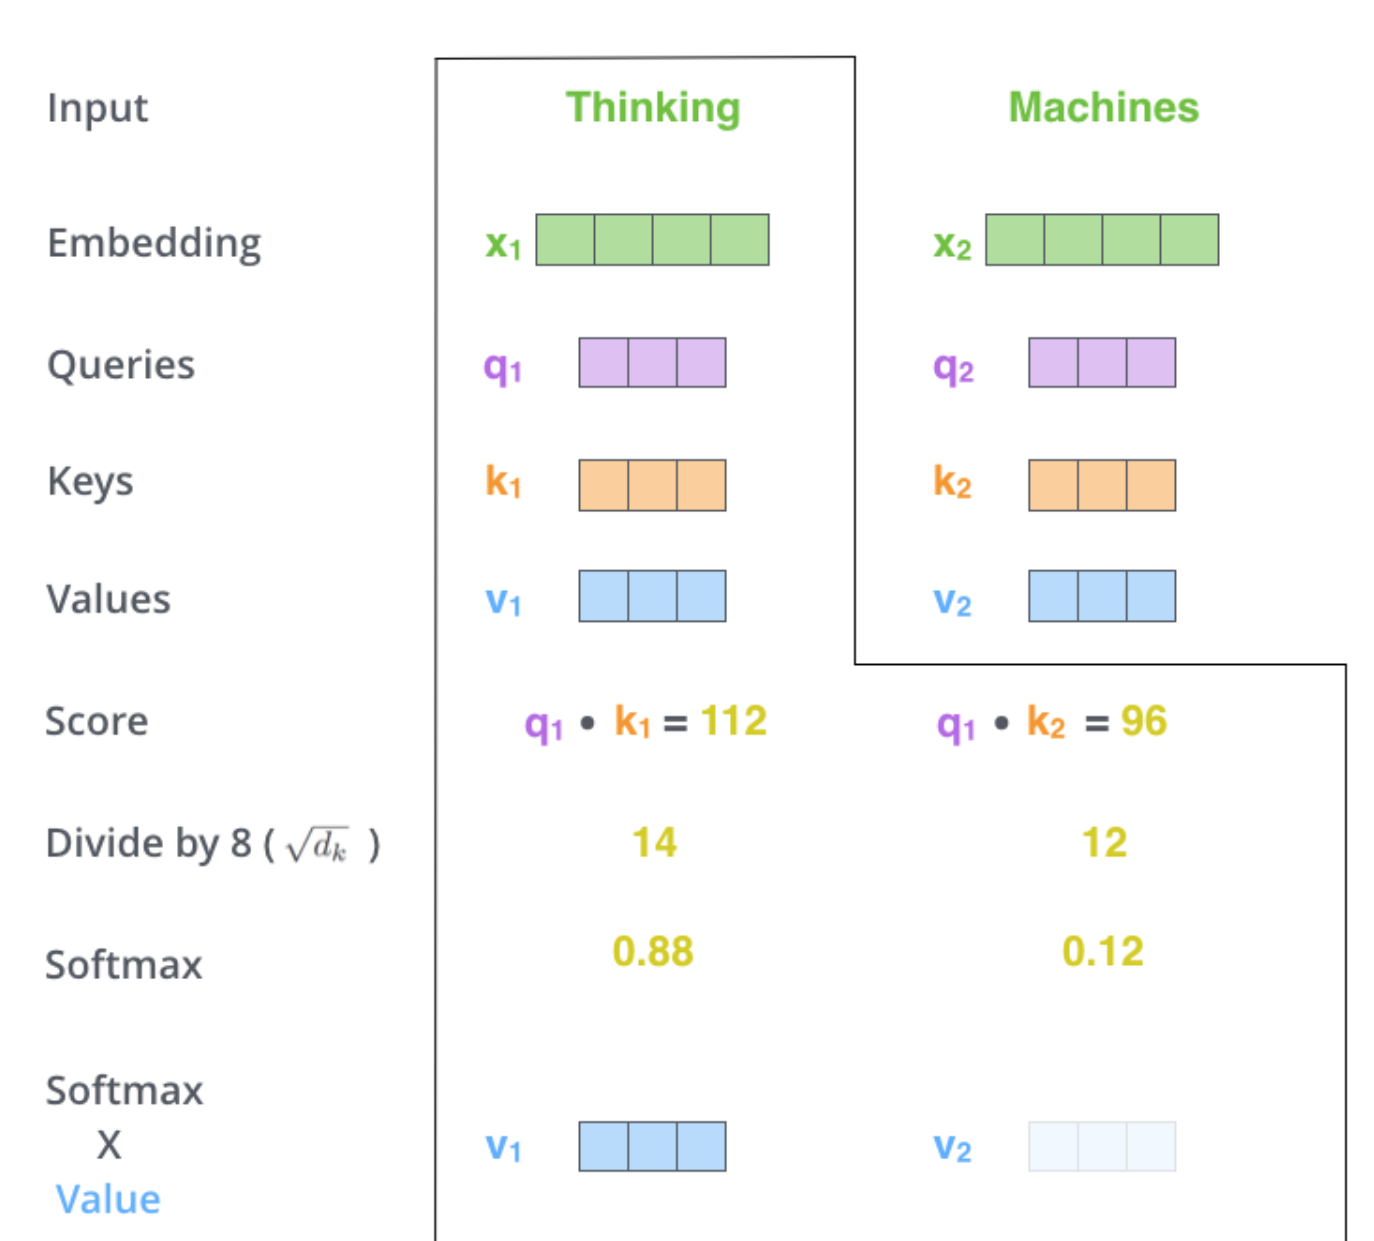

W ten sposób po zebraniu naszego attention w całość, zyskaliśmy nasz nowy wektor, który dalej wyślemy w naszej sieci - do warstwty feed forward. (O dalszej architekturze na kolejnych zajęciach)

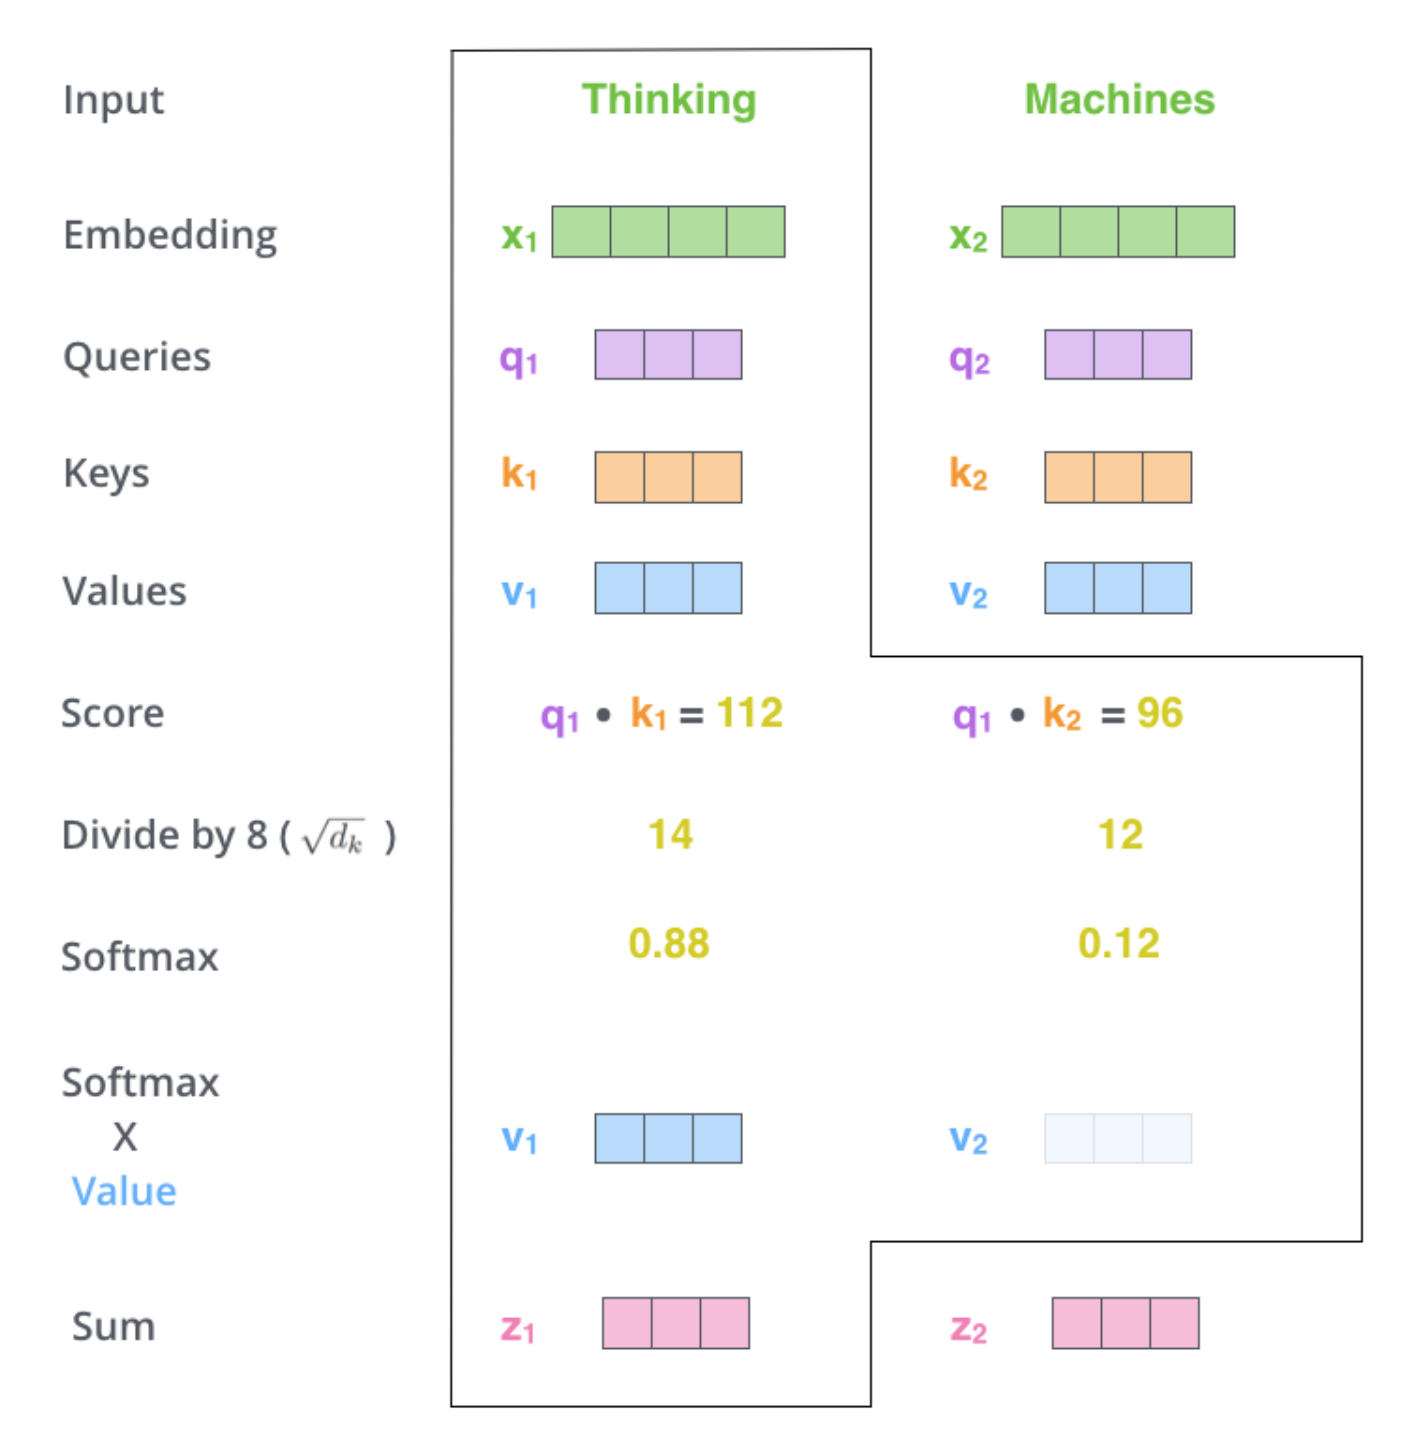

### 5 Obliczenie attention - na macierzach

Wektory dobrze wizualizują co siedzieje w attention, ale w rzeczywistym scenariuszu wszystko robimy na macierzach - aby było szybciej.

Analogicznie jak z wektorami towrzymy macierze query, key i value:

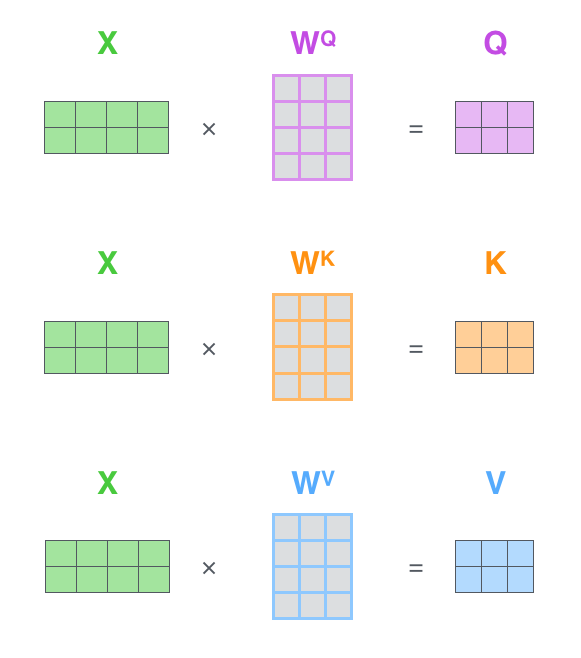

(każdy wiersz w X odpowiada danemu słowu - to co wcześniej robiliśmy koło siebie, teraz zrobimy "na raz")

W skrócie:
1. Przemnażamy query i key (key jest transponowane, aby macierze się zgadzały)
2. Dzielimy na pierwiastek z wymiaru key (k)
3. Używamy softmaxa
4. Mnożymy razy wartości values
5. Tadam 🐱

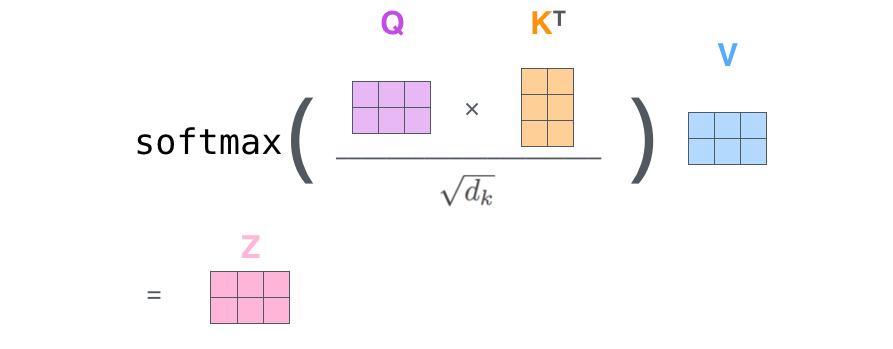

In [2]:
import numpy as np
import math

def softmax(x, axis=-1):
    """
    Standardowy softmax (stabilny numerycznie).
    Dla każdej linii (np. dla każdego tokena w sekwencji)
    przelicza wartości na rozkład prawdopodobieństwa.
    """
    x_max = np.max(x, axis=axis, keepdims=True)
    e_x = np.exp(x - x_max)  # stabilizacja numeryczna
    return e_x / np.sum(e_x, axis=axis, keepdims=True)

def scaled_dot_product_attention(Q, K, V, mask=None, verbose=True):
    """
    Implementacja mechanizmu Scaled Dot-Product Attention krok po kroku.

    Parametry:
    -----------
    Q : np.ndarray, shape (..., seq_len_q, dk)
        Zapytania (queries)
    K : np.ndarray, shape (..., seq_len_k, dk)
        Klucze (keys)
    V : np.ndarray, shape (..., seq_len_k, dv)
        Wartości (values)
    mask : np.ndarray lub None
        Maska (np. do maskowania paddingu lub przyszłych tokenów)
    verbose : bool
        Czy drukować pośrednie wyniki

    Zwraca:
    --------
    output : (..., seq_len_q, dv)
        Wynik ważonej sumy wartości
    attn_weights : (..., seq_len_q, seq_len_k)
        Wagi uwagi po softmaxie
    """

    dk = Q.shape[-1]

    if verbose:
        print("==== INPUTS ====")
        print(f"Q shape: {Q.shape}")
        print(f"K shape: {K.shape}")
        print(f"V shape: {V.shape}\n")
        print("Q =", np.round(Q, 3))
        print("K =", np.round(K, 3))
        print("V =", np.round(V, 3))
        print("================\n")

    # Liczymy „scores” – czyli miarę podobieństwa zapytań Q i kluczy K
    scores = np.matmul(Q, K.transpose(0, 2, 1)) if Q.ndim == 3 else np.matmul(Q, K.T)
    if verbose:
        print("Scores (QK^T):")
        print(np.round(scores, 3), "\n")

    # Skalowanie przez sqrt(dk)
    scores = scores / math.sqrt(dk)
    if verbose:
        print(f"Scaled scores (dzielone przez sqrt({dk}) = {math.sqrt(dk):.3f}):")
        print(np.round(scores, 3), "\n")

    # Dodatke: Dodajemy maskę (jeśli jest)
    if mask is not None:
        scores = scores + mask
        if verbose:
            print("After adding mask:")
            print(np.round(scores, 3), "\n")

    # Softmax — zamienia scores na rozkład wag uwagi
    attn_weights = softmax(scores, axis=-1)
    if verbose:
        print("Attention weights po softmax:")
        print(np.round(attn_weights, 3))
        print(f"Każdy wiersz sumuje się do: {np.sum(attn_weights, axis=-1)}\n")

    # Mnożymy przez V, żeby uzyskać ważoną sumę wartości
    output = np.matmul(attn_weights, V)
    if verbose:
        print("Wynik po pomnożeniu przez V:")
        print(np.round(output, 3))
        print("============================\n")

    return output, attn_weights


# 🔍 Quick sanity check
np.random.seed(0)
Q = np.random.rand(1, 3, 4)  # batch=1, query len=3, dk=4
K = np.random.rand(1, 5, 4)  # key len=5
V = np.random.rand(1, 5, 6)  # value dim=6

out, w = scaled_dot_product_attention(Q, K, V)

print("FINAL OUTPUT SHAPES:")
print("Output shape:", out.shape)
print("Weights shape:", w.shape)

==== INPUTS ====
Q shape: (1, 3, 4)
K shape: (1, 5, 4)
V shape: (1, 5, 6)

Q = [[[0.549 0.715 0.603 0.545]
  [0.424 0.646 0.438 0.892]
  [0.964 0.383 0.792 0.529]]]
K = [[[0.568 0.926 0.071 0.087]
  [0.02  0.833 0.778 0.87 ]
  [0.979 0.799 0.461 0.781]
  [0.118 0.64  0.143 0.945]
  [0.522 0.415 0.265 0.774]]]
V = [[[0.456 0.568 0.019 0.618 0.612 0.617]
  [0.944 0.682 0.36  0.437 0.698 0.06 ]
  [0.667 0.671 0.21  0.129 0.315 0.364]
  [0.57  0.439 0.988 0.102 0.209 0.161]
  [0.653 0.253 0.466 0.244 0.159 0.11 ]]]

Scores (QK^T):
[[[1.064 1.55  1.812 1.124 1.164]
  [0.947 1.663 1.829 1.369 1.295]
  [1.005 1.415 2.028 0.972 1.281]]] 

Scaled scores (dzielone przez sqrt(4) = 2.000):
[[[0.532 0.775 0.906 0.562 0.582]
  [0.474 0.831 0.914 0.684 0.648]
  [0.502 0.707 1.014 0.486 0.64 ]]] 

Attention weights po softmax:
[[[0.172 0.219 0.25  0.177 0.181]
  [0.156 0.223 0.242 0.193 0.186]
  [0.166 0.204 0.277 0.163 0.19 ]]]
Każdy wiersz sumuje się do: [[1. 1. 1.]]

Wynik po pomnożeniu przez V:
[[

Q shape: (1, 4, 4)
K shape: (1, 4, 4)
V shape: (1, 4, 6)

Attention weights shape: (1, 4, 4)
Każdy wiersz sumuje się do 1 → [[1. 1. 1. 1.]]


/usr/local/lib/python3.13/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 129504 (\N{BRAIN}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)


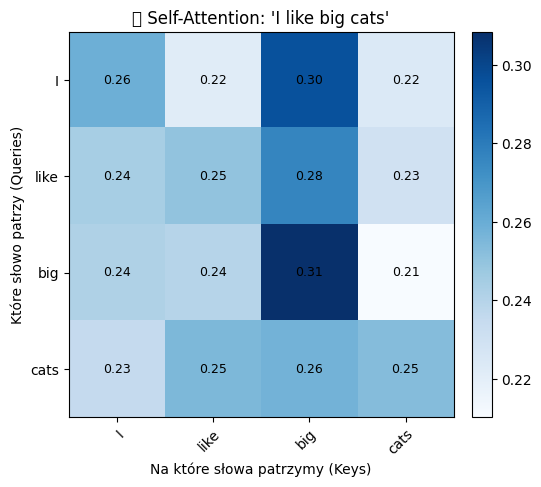

In [3]:
# SELF-ATTENTION DLA JEDNEGO ZDANIA

import numpy as np
import matplotlib.pyplot as plt
import math

# softmax i funkcja attention
def softmax(x, axis=-1):
    x_max = np.max(x, axis=axis, keepdims=True)
    e_x = np.exp(x - x_max)
    return e_x / np.sum(e_x, axis=axis, keepdims=True)

def scaled_dot_product_attention(Q, K, V, mask=None):
    dk = Q.shape[-1]
    scores = np.matmul(Q, K.transpose(0, 2, 1)) / math.sqrt(dk)
    if mask is not None:
        scores = scores + mask
    attn_weights = softmax(scores, axis=-1)
    output = np.matmul(attn_weights, V)
    return output, attn_weights


# Dane wejściowe (symulacja)
np.random.seed(42)

tokens = ["I", "like", "big", "cats"]
seq_len = len(tokens)
d_k = 4
d_v = 6

Q = np.random.rand(1, seq_len, d_k)
K = np.random.rand(1, seq_len, d_k)
V = np.random.rand(1, seq_len, d_v)

print("Q shape:", Q.shape)
print("K shape:", K.shape)
print("V shape:", V.shape)

# Obliczenie uwagi
out, attn_weights = scaled_dot_product_attention(Q, K, V)

print("\nAttention weights shape:", attn_weights.shape)
print("Każdy wiersz sumuje się do 1 →", np.sum(attn_weights, axis=-1))

# Wizualizacja wag uwagi
fig, ax = plt.subplots(figsize=(6, 5))
im = ax.imshow(attn_weights[0], cmap="Blues")
ax.set_xticks(np.arange(seq_len))
ax.set_yticks(np.arange(seq_len))
ax.set_xticklabels(tokens)
ax.set_yticklabels(tokens)
plt.setp(ax.get_xticklabels(), rotation=45, ha="right", rotation_mode="anchor")
ax.set_xlabel("Na które słowa patrzymy (Keys)")
ax.set_ylabel("Które słowo patrzy (Queries)")
ax.set_title("🧠 Self-Attention: 'I like big cats'")

for i in range(seq_len):
    for j in range(seq_len):
        text = ax.text(j, i, f"{attn_weights[0, i, j]:.2f}",
                       ha="center", va="center", color="black", fontsize=9)

plt.colorbar(im, fraction=0.046, pad=0.04)
plt.show()


## Multi-Head Attention

Jakby sam mechanizm uwagi był za prosty :) W transformerach mozemy spotkać coś co nazywa się Multi-Head Attention

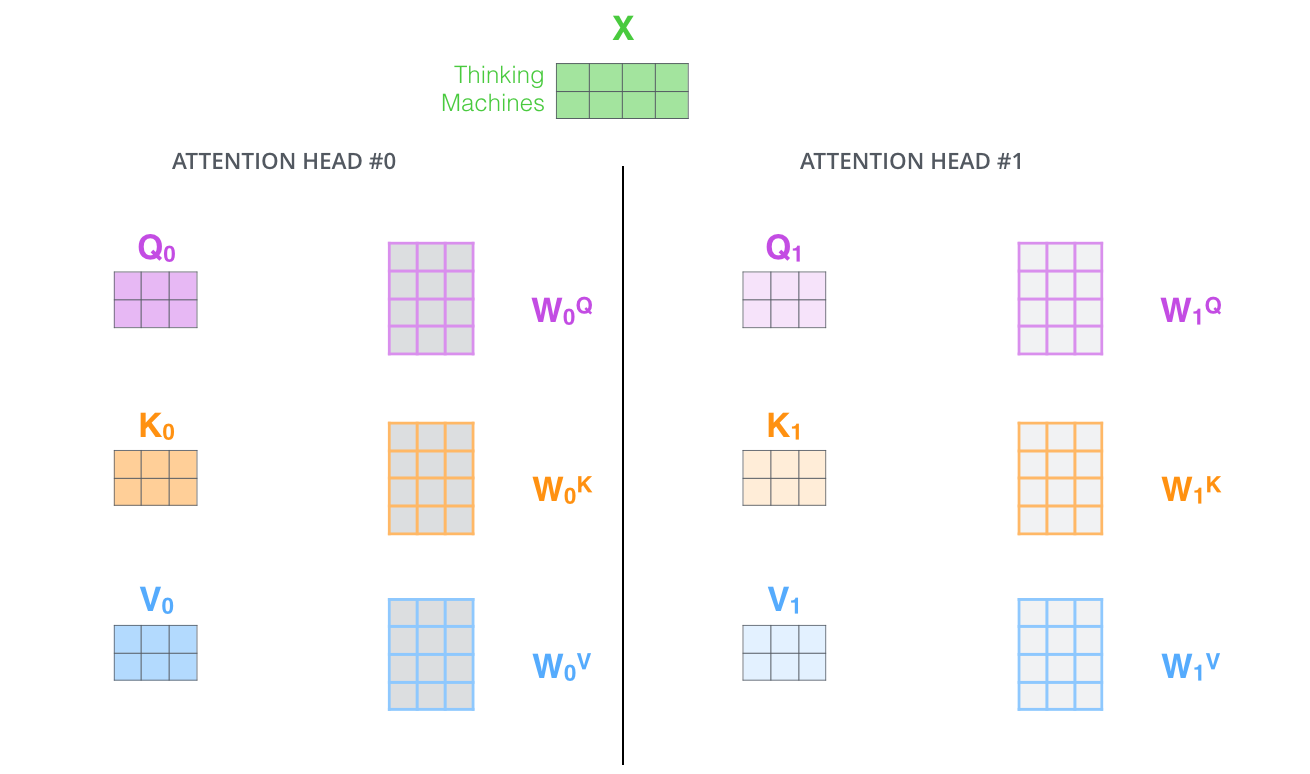

Jest to rozwinięcie samego attention, która pozwala modelowi uczyć się wielu sposobów "patrzenia" na kontekst słów w zdaniu.

Zamiast jednej atencji (jednego zestawu Q, K, V), tworzymy ich kilka (np. 8), a następnie łączymy wyniki w jedną reprezentację.

In [4]:
import torch
import torch.nn as nn
import torch.nn.functional as F

torch.manual_seed(0)

### 1 Wejście

Wyobraźmy sobie zdanie: "The animal didn't cross the street because it was too tired".

Dla uproszczenia stwórzmy losowe wektory (embeddingi) dla 12 słów.



In [5]:
seq_len = 12   # liczba słów
d_model = 64  # rozmiar wektora (embedding)
x = torch.rand(seq_len, d_model)
print("Kształt wejścia:", x.shape)

Kształt wejścia: torch.Size([12, 64])


# 2 Attention (Single-Head)
Przekształca każde słowo (wektor) w nowe reprezentacje używając trzech macierzy wag: W_Q, W_K, W_V (to co wcześniej)

In [6]:
d_k = d_model  # dla prostoty
W_Q = nn.Linear(d_model, d_k)
W_K = nn.Linear(d_model, d_k)
W_V = nn.Linear(d_model, d_k)

Q = W_Q(x)
K = W_K(x)
V = W_V(x)

print("Kształty Q, K, V:", Q.shape, K.shape, V.shape)


Kształty Q, K, V: torch.Size([12, 64]) torch.Size([12, 64]) torch.Size([12, 64])


In [7]:
scores = torch.matmul(Q, K.T) / torch.sqrt(torch.tensor(d_k, dtype=torch.float32))
attn_weights = F.softmax(scores, dim=-1)
Z = torch.matmul(attn_weights, V)

print("Kształt macierzy wynikowej Z (jedna głowa):", Z.shape)

Kształt macierzy wynikowej Z (jedna głowa): torch.Size([12, 64])


### 3 Multi head attention

 Teraz zamiast jednej atencji, tworzymy kilka "głów" — każda z własnymi W_Q, W_K, W_V. Każda głowa "patrzy" na dane w inny sposób

In [8]:
num_heads = 8
head_dim = d_model // num_heads  # 64 rozmiar modelu / 8 głow = 8 rozmiar jednej głowy

W_Q = nn.Linear(d_model, d_model)
W_K = nn.Linear(d_model, d_model)
W_V = nn.Linear(d_model, d_model)

Q = W_Q(x).view(seq_len, num_heads, head_dim)
K = W_K(x).view(seq_len, num_heads, head_dim)
V = W_V(x).view(seq_len, num_heads, head_dim)

print("Kształt Q po podziale na głowy:", Q.shape)  # [12, 8, 8]


Kształt Q po podziale na głowy: torch.Size([12, 8, 8])


Obliczamy uwagę osobno dla każdej głowy

In [9]:
Z_heads = []
for h in range(num_heads):
    q, k, v = Q[:, h, :], K[:, h, :], V[:, h, :]
    scores = torch.matmul(q, k.T) / torch.sqrt(torch.tensor(head_dim, dtype=torch.float32))
    attn = F.softmax(scores, dim=-1)
    z = torch.matmul(attn, v)
    Z_heads.append(z)

print("Z_heads:", [h.shape for h in Z_heads], "Len Z_heads:", len(Z_heads))

# [12, 64] po połączeniu wszystkich głów - to co mieliśmy przed
Z_multi = torch.cat(Z_heads, dim=-1)
print("Z po połączeniu wszystkich głów:", Z_multi.shape)

Z_heads: [torch.Size([12, 8]), torch.Size([12, 8]), torch.Size([12, 8]), torch.Size([12, 8]), torch.Size([12, 8]), torch.Size([12, 8]), torch.Size([12, 8]), torch.Size([12, 8])] Len Z_heads: 8
Z po połączeniu wszystkich głów: torch.Size([12, 64])


Każda głowa:
*  z_i.shape = [12, 8] → czyli 12 tokenów × 8 cech (bo head_dim = 8).

Mamy 8 głów * 8 cech = 64 → To jest surowe połączenie wyników głów — wszystkie perspektywy „obok siebie”.

Warstwa łączenia (Output Projection) - Po złączeniu wszystkich głów, mnożymy przez macierz WO, żeby wrócić do wymiaru d_model. To przygotowuje dane do kolejnych warstw transformera.

In [10]:
W_O = nn.Linear(d_model, d_model)
output = W_O(Z_multi)
print("Ostateczny kształt po WO:", output.shape)


Ostateczny kształt po WO: torch.Size([12, 64])


Dlaczego nie kończymy na łączeniu wszystkich głów?

Bo bez W_O:
*  każda głowa miałaby „swoje” cechy, ale nie byłoby interakcji między nimi,
sieć dalej miałaby tensor [12, 64] — niezgodny z oczekiwanym d_model.

*  W_O gwarantuje, że każdy token po multi-head attention ma z powrotem wektor o tym samym rozmiarze, co na wejściu (d_model) — dzięki czemu architektura Transformera pozostaje spójna w każdej warstwie.


```
         ┌────────────┐
Input X ─►   Q,K,V    │
         └────────────┘
                │
        ┌───────▼──────────────────────────────────┐
        │  Head 1 ... Head 8 (różne przestrzenie)  │
        └───────▲──────────────────────────────────┘
                │
           concat ( [12, 64] )
                │
           WO Linear Layer
                │
           output ( [12, 16] )

```



Chwila, chwila.. przecież mieliśmy wymiar [12, 64] po złączeniu głów i po warstwie łaczenia, która ma wrócić nas do wymiaru d_model mamy dokładnie ten sam wymiar?! Co to za oszustwa 😠

Jeśli w modelu:

In [11]:
d_model == num_heads * head_dim

True

to:
* po konkatenacji (concat) masz [seq_len, 64]
* po W_O dalej masz [seq_len, 64]

Więc — tak, wymiar liczbowo się nie zmienia.

W_O **nie** istnieje po to, żeby zmienić rozmiar tensora.
Istnieje po to, żeby nauczyć się **mieszać informacje z różnych głów.**

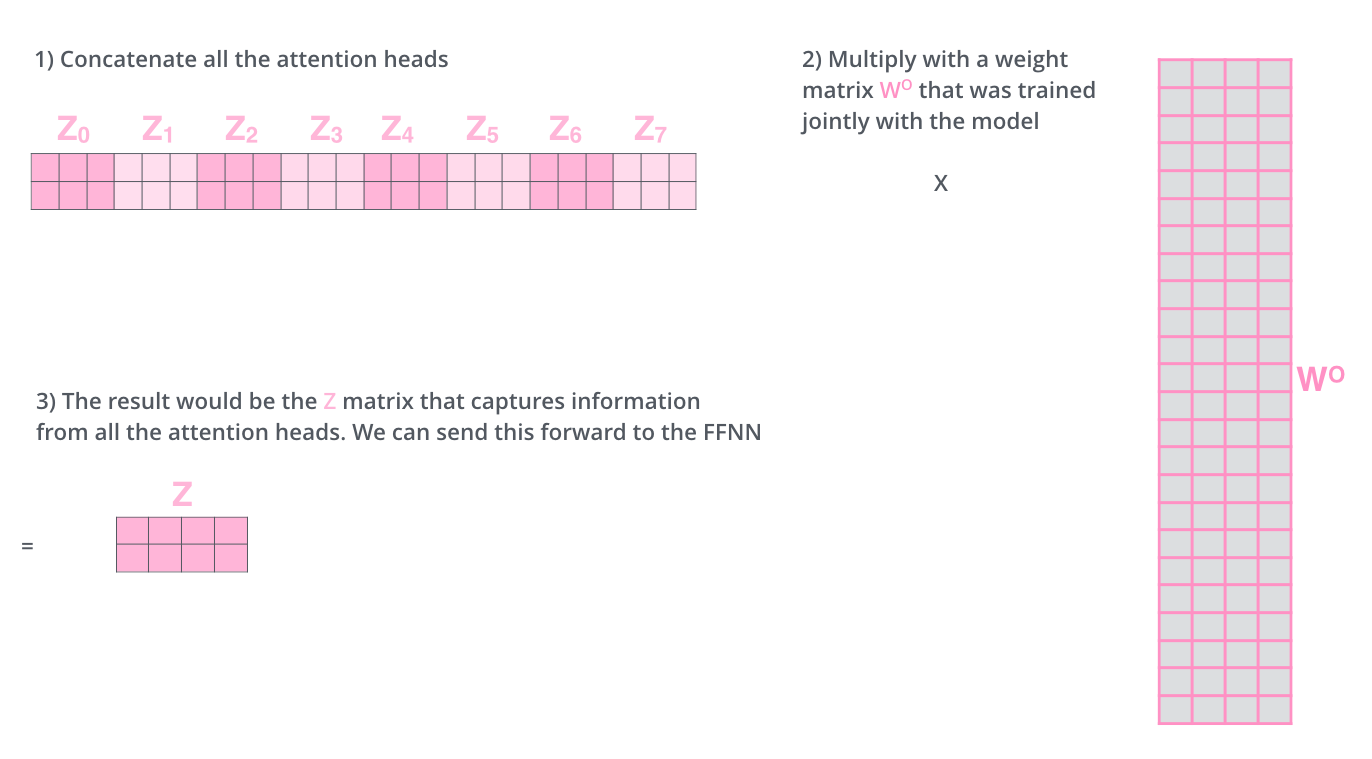

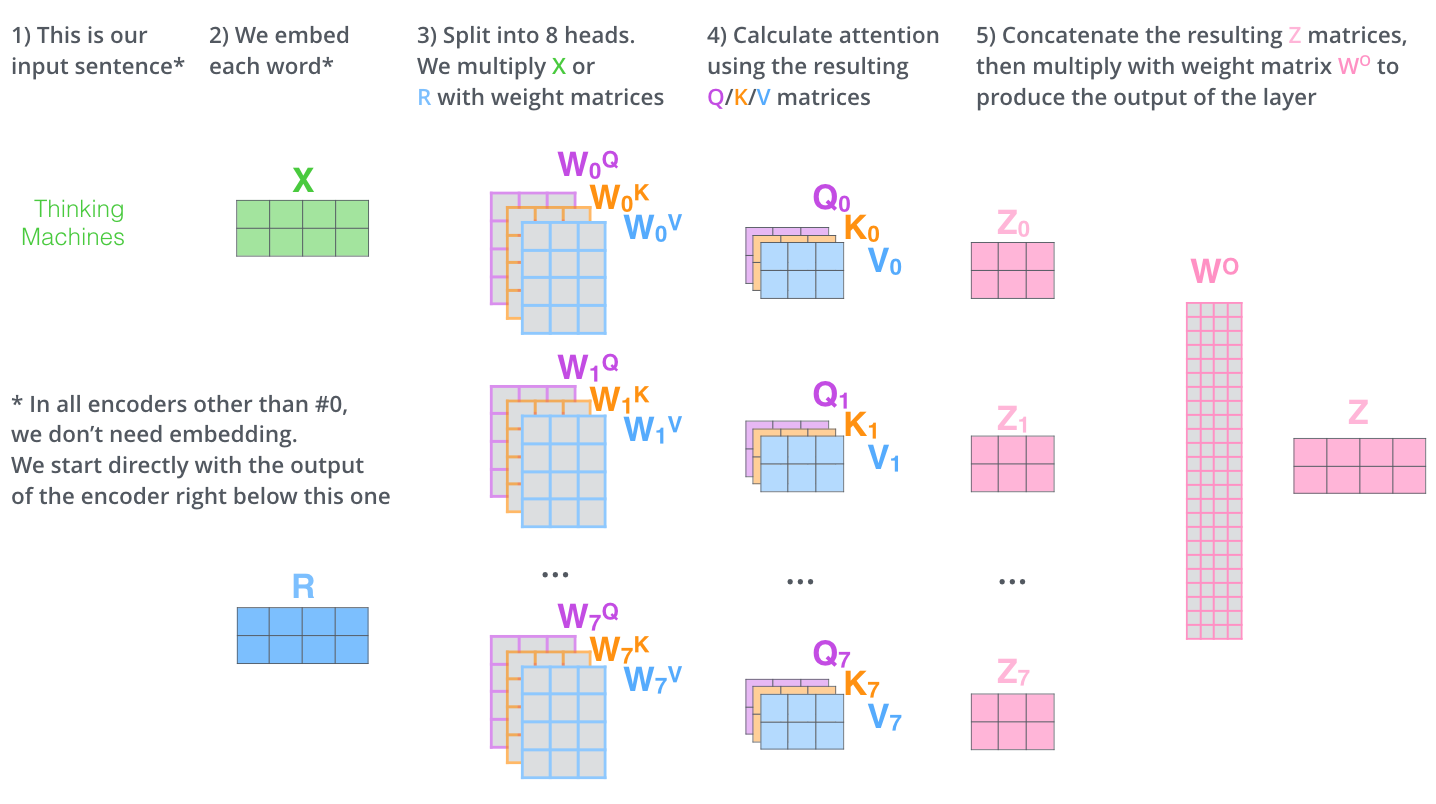

Teraz możemy porównać jak przykładowe dwie głowy traktują nasze zdanie wyjściowe:

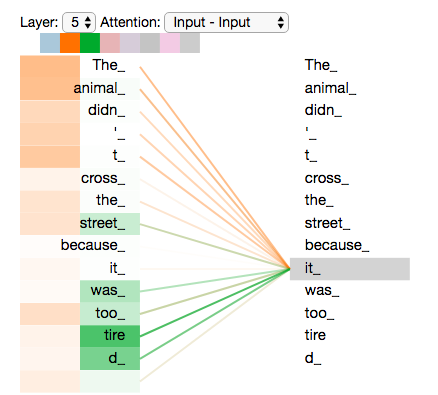

Ale po dodaniu 8 głów:

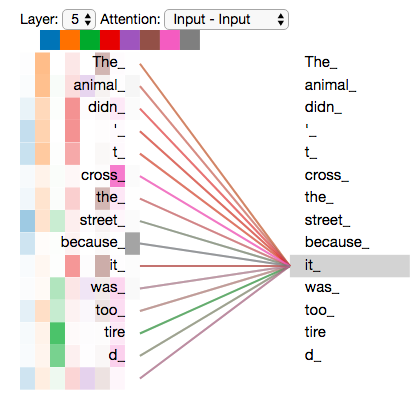

# Zadania

## Zadanie 1

Liczymy attention:

1. Utwórz wektory:
  *  Q = [1, 0]
  *  K1 = [1, 1]
  *  K2 = [0, 1]
  *  V1 = [2, 0]
  *  V2 = [0, 2]

2. Oblicz podobieństwo - score1 i score2: Q * K^T

3. Skalujemy - scaled1 i scaled2: dzielenie przez sqrt(d_k), uznajmy że d_k = 2

4. zastosuj softmax - probs

(Podpowiedź: To już nie będzie pojedynczy numerek a wektor: `scaled_scores = np.array([scaled1, scaled2])` i na tym robimy softmax )

5. Suma ważona Values - output

6. Odpowiedz na pytanie zawarte w print - które słowo (Key) miało największy wpływ na wynik?


In [16]:
# 0) Dane
# TODO

Q = np.array([1, 0])
K1 = np.array([1, 1])
K2 = np.array([0, 1])
V1 = np.array([2, 0])
V2 = np.array([0, 2])

# 1) podobieństwa
# TODO
score1 = np.dot(Q, K1)
score2 = np.dot(Q, K2)
scores = np.array([score1, score2])

# 2) scaled scores
# TODO
d_k = 2
scaled_scores = scores / math.sqrt(d_k)

# 3) softmax
def softmax(x):
    exp_x = np.exp(x - np.max(x))
    return exp_x / np.sum(exp_x)

probs = softmax(scaled_scores)

# 4) weighted sum of V
output = probs[0] * V1 + probs[1] * V2

# Print zadanie 1
print("Scores: ", scores)
print("Scaled scores: ", scaled_scores)
print("Softmax probabilities: ", probs)
print("Output attention (wektor): ", output)
print("Interpretacja: Największy wpływ na wynik miał wektor K1, ponieważ jego wynik prawdopodobieństwa (ok. 67%) był wyższy niż dla K2 (ok. 33%).\n")


Scores:  [1 0]
Scaled scores:  [0.70710678 0.        ]
Softmax probabilities:  [0.66976155 0.33023845]
Output attention (wektor):  [1.3395231 0.6604769]
Interpretacja: # TODO



## Zadanie 2

Utwórz prostą implementację multi-head attention dla dwóch głów, korzystając z  z Zadania 1.

Każda głowa będzie miała własne wektory Qi, Ki, Vi, maciesze Wq, Wk i Wv oraz własne wyniki softmax i output.

Na końcu połączysz wyniki obu głów (konkatenacja), aby uzyskać końcowy wektor.

Zwizualizuj wagi uwagi - forma dowolna

Last vector (after concatenate heads:
 [[1.3395231  0.6604769  0.64086908 0.84891365]
 [1.174958   0.825042   0.64715586 0.84105518]]


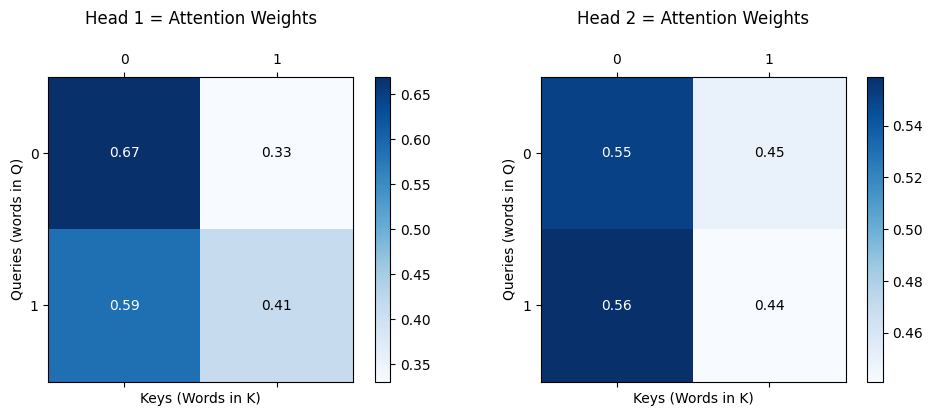

In [17]:
import numpy as np
import math
import matplotlib.pyplot as plt

def softmax(x):
    exp_x = np.exp(x - np.max(x, axis=-1, keepdims=True))
    return exp_x / np.sum(exp_x, axis=-1, keepdims=True)

def scaled_dot_product_attention(Q, K, V):
    d_k = Q.shape[-1]
    scores = np.dot(Q, K.T)
    scaled_scores = scores / math.sqrt(d_k)
    weights = softmax(scaled_scores)
    output = np.dot(weights, V)
    return output, weights


# Dane bazowe
K = np.array([[1., 1.], [0., 1.]])
V = np.array([[2., 0.], [0., 2.]])
Q = np.array([[1., 0.], [0.5, 1.0]])  # dwa zapytania dla dwóch głów

d_model = 2   # wymiar wejściowy
d_head = 2    # wymiar każdej głowy

# Głowa 1
Wq1 = np.array([[1., 0.], [0., 1.]])
Wk1 = np.array([[1., 0.], [0., 1.]])
Wv1 = np.array([[1., 0.], [0., 1.]])

# Głowa 2
Wq2 = np.array([[0.5, 0.2], [0.1, 0.7]])
Wk2 = np.array([[0.8, 0.1], [0.3, 0.9]])
Wv2 = np.array([[0.6, 0.4], [0.2, 0.8]])

# Połączenie - polecam do pętli będzie tak wygodniej :)
Wq_heads = [Wq1, Wq2]
Wk_heads = [Wk1, Wk2]
Wv_heads = [Wv1, Wv2]

head_outputs = []
head_weights = []

# TODO
for i in range(2):
  Qi = np.dot(Q, Wq_heads[i])
  Ki = np.dot(K, Wq_heads[i])
  Vi = np.dot(V, Wq_heads[i])

  out, weights = scaled_dot_product_attention(Qi, Ki, Vi)
  head_outputs.append(out)
  head_weights.append(weights)

final_output = np.concatenate(head_outputs, axis=-1)
print("Last vector (after concatenate heads:\n", final_output)

fig, axes = plt.subplots(1, 2, figsize=(10, 4))
for i in range(2):
  ax = axes[i]
  cax = ax.matshow(head_weights[i], cmap='Blues')
  fig.colorbar(cax, ax=ax)

  ax.set_title(f"Head {i+1} = Attention Weights\n")
  ax.set_xlabel("Keys (Words in K)")
  ax.set_ylabel('Queries (words in Q)')

  for (y, x), val in np.ndenumerate(head_weights[i]):
    ax.text(x, y, f'{val:.2f}', ha='center', va='center', color='white' if val > 0.5 else 'black')
plt.tight_layout()
plt.show()